# Exploratory Data Analysis – Online Retail II

### SWYNEX Technologies – Data Analytics Internship | Task 2

**Objective:** Explore the cleaned Online Retail II dataset, analyze revenue and business performance, identify important trends and anomalies, and produce reproducible tables and visualizations.

### Analysis areas
- Dataset quality and structure
- Transaction type distribution
- Revenue trends by month and year
- Product performance by revenue and quantity
- Country performance by transactions and revenue
- Customer contribution
- Returns/cancellations and their financial impact
- High-value statistical anomaly detection
- Evidence-based business insights

> **Important:** This notebook is designed to run on the cleaned CSV produced in **Task 1**. It does not silently remove meaningful return/cancellation transactions.

## 1. Import Libraries

In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

## 2. Load the Cleaned Dataset

Expected project structure:

```text
SWYNEX-Exploratory-Data-Analysis/
├── data/
│   └── cleaned/
│       └── online_retail_II_cleaned.csv
├── notebooks/
│   └── 02_Exploratory_Data_Analysis_FINAL_CORRECTED.ipynb
├── output/
└── visualizations/
```

Run this notebook from the `notebooks/` folder.

In [63]:
cleaned_file = Path("../data/cleaned/online_retail_II_cleaned.csv")
output_dir = Path("../output")
visualization_dir = Path("../visualizations")

output_dir.mkdir(parents=True, exist_ok=True)
visualization_dir.mkdir(parents=True, exist_ok=True)

if not cleaned_file.exists():
    raise FileNotFoundError(
        f"Cleaned dataset not found at: {cleaned_file.resolve()}\n"
        "Make sure Task 1's cleaned CSV is copied to data/cleaned/."
    )

df = pd.read_csv(cleaned_file, parse_dates=["InvoiceDate"])

print(f"Dataset loaded successfully: {cleaned_file.resolve()}")
print(f"Shape: {df.shape}")

Dataset loaded successfully: C:\Users\Admin\OneDrive\Desktop\SWYNEX Technologies Internship Tasks\SWYNEX-Exploratory-Data-Analysis\data\cleaned\online_retail_II_cleaned.csv
Shape: (1033031, 16)


## 3. Dataset Overview

In [64]:
overview = pd.Series({
    "Records": len(df),
    "Columns": df.shape[1],
    "Unique invoices": df["Invoice"].nunique(),
    "Unique products": df["StockCode"].nunique(),
    "Unique countries": df["Country"].nunique(),
    "Identified customers": df["Customer ID"].nunique(),
    "Date range start": df["InvoiceDate"].min(),
    "Date range end": df["InvoiceDate"].max(),
    "Total quantity": df["Quantity"].sum(),
    "Total net revenue": df["Revenue"].sum()
})

display(overview.to_frame("Value"))

,Value
Records,1033031
Columns,16
Unique invoices,53623
Unique products,5305
Unique countries,43
Identified customers,5942
Date range start,2009-12-01 07:45:00
Date range end,2011-12-09 12:50:00
Total quantity,10409774
Total net revenue,"19,014,209.84"


### Data Types, Missing Values and Duplicate Validation

In [65]:
quality = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Missing Values": df.isna().sum(),
    "Missing %": (df.isna().mean() * 100).round(2),
    "Unique Values": df.nunique(dropna=True)
})

display(quality)
quality.to_csv(output_dir / "eda_data_quality.csv", index=True)

print("Duplicate records:", df.duplicated().sum())
print("Missing InvoiceDate:", df["InvoiceDate"].isna().sum())

,Data Type,Missing Values,Missing %,Unique Values
Invoice,str,0,0.00,53623
StockCode,str,0,0.00,5305
Description,str,363,0.04,5698
Quantity,int64,0,0.00,1057
InvoiceDate,datetime64[us],0,0.00,47631
Price,float64,0,0.00,2803
Customer ID,float64,235146,22.76,5942
Country,str,0,0.00,43
IsCancellation,bool,0,0.00,2
IsZeroPrice,bool,0,0.00,2


Duplicate records: 0
Missing InvoiceDate: 0


## 4. Descriptive Statistics

In [66]:
numeric_summary = df[["Quantity", "Price", "Revenue"]].describe().T
display(numeric_summary)

numeric_summary.to_csv(output_dir / "summary_statistics.csv")

,count,mean,std,min,25%,50%,75%,max
Quantity,"1,033,031.00",10.08,175.20,"-80,995.00",1.00,3.00,10.00,"80,995.00"
Price,"1,033,031.00",4.77,92.84,0.00,1.25,2.10,4.15,"38,970.00"
Revenue,"1,033,031.00",18.41,284.72,"-168,469.60",3.75,9.92,17.70,"168,469.60"


## 5. Transaction Type Analysis

The cleaned dataset contains three business event categories:
- **Sale**
- **Cancellation/Return**
- **Adjustment**

Returns/cancellations are retained because they are meaningful business events rather than automatically treated as bad data.

In [67]:
transaction_summary = (
    df.groupby("TransactionType")
      .agg(
          Transactions=("Invoice", "size"),
          Unique_Invoices=("Invoice", "nunique"),
          Quantity=("Quantity", "sum"),
          Revenue=("Revenue", "sum")
      )
      .sort_values("Transactions")
)

display(transaction_summary)

transaction_summary.to_csv(output_dir / "transaction_summary.csv")

,Transactions,Unique_Invoices,Quantity,Revenue
TransactionType,,,,
Adjustment,3393,3393,-569314,0.00
Cancellation/Return,19104,8292,-476819,"-1,462,050.61"
Sale,1010534,41938,11455907,"20,476,260.45"


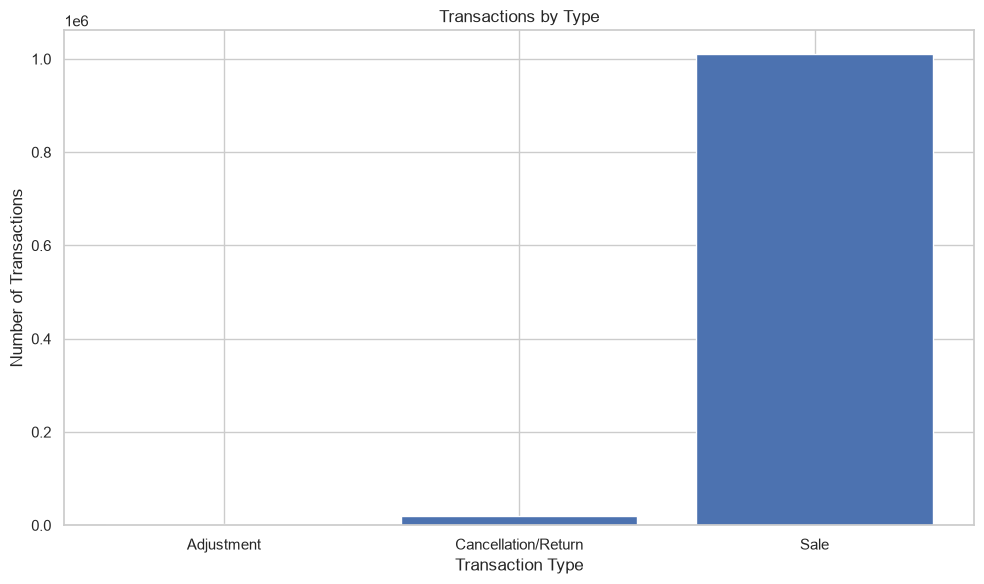

In [68]:
plt.figure(figsize=(10, 6))
transaction_plot = transaction_summary.reset_index()

plt.bar(
    transaction_plot["TransactionType"],
    transaction_plot["Transactions"]
)

plt.title("Transactions by Type")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.savefig(
    visualization_dir / "transaction_type_distribution.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

## 6. Revenue Analysis

Two revenue perspectives are used:

- **Net Revenue:** all cleaned transaction rows, including returns/cancellations and adjustments.
- **Sales Revenue:** only rows classified as `Sale`.

For the main trend analysis, net revenue is used so that return/cancellation impact remains visible.

In [69]:
sales_df = df[df["TransactionType"].eq("Sale")].copy()

sales_summary = pd.Series({
    "Sale line records": len(sales_df),
    "Unique sale invoices": sales_df["Invoice"].nunique(),
    "Sales revenue": sales_df["Revenue"].sum(),
    "Average sale-line revenue": sales_df["Revenue"].mean(),
    "Positive revenue records": (sales_df["Revenue"] > 0).sum()
})

display(sales_summary.to_frame("Value"))

,Value
Sale line records,"1,010,534.00"
Unique sale invoices,"41,938.00"
Sales revenue,"20,476,260.45"
Average sale-line revenue,20.26
Positive revenue records,"1,007,913.00"


### Monthly Revenue Trend

,YearMonth,Net_Revenue,Quantity,Invoice_Count
0,2009-12,"796,648.50",418570,2330
1,2010-01,"622,479.50",374510,1633
2,2010-02,"531,265.37",367501,1969
3,2010-03,"763,247.24",488012,2367
4,2010-04,"641,521.05",350477,1891
5,2010-05,"613,270.72",362771,2418
6,2010-06,"677,073.87",386447,2216
7,2010-07,"617,365.48",301175,2016
8,2010-08,"654,774.39",450775,1877
9,2010-09,"851,105.96",476808,2375


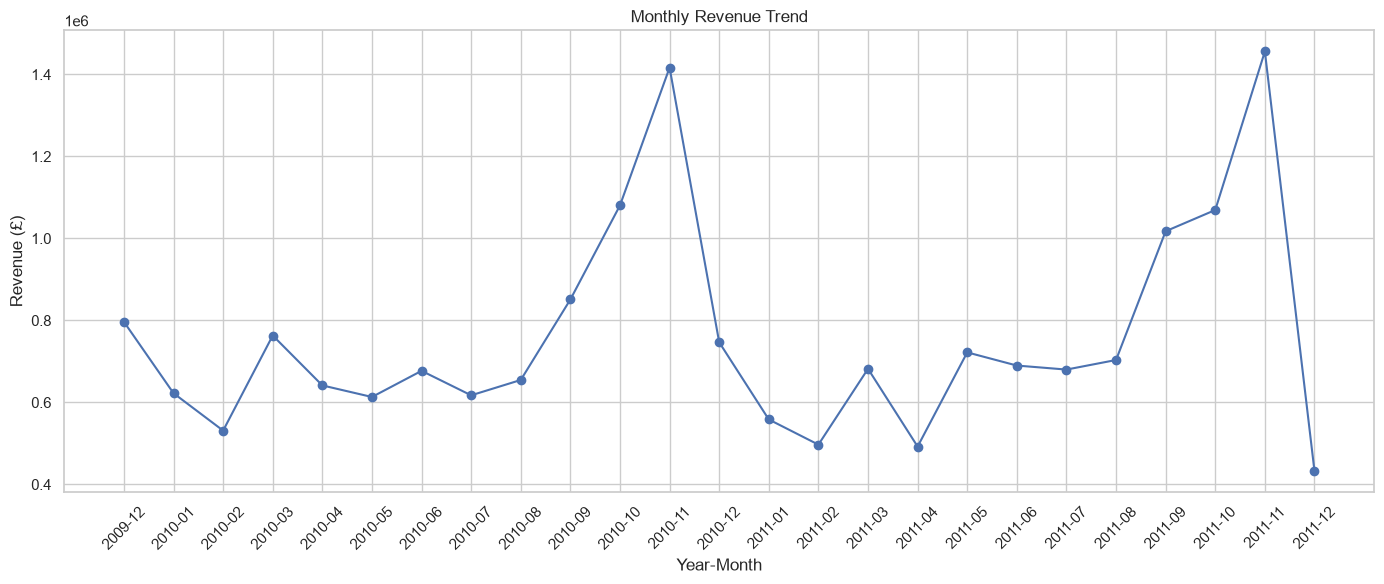

In [70]:
monthly = (
    df.groupby("YearMonth")
      .agg(
          Net_Revenue=("Revenue", "sum"),
          Quantity=("Quantity", "sum"),
          Invoice_Count=("Invoice", "nunique")
      )
      .reset_index()
)

monthly["YearMonth"] = monthly["YearMonth"].astype(str)

display(monthly)

monthly.to_csv(output_dir / "monthly_revenue.csv", index=False)

plt.figure(figsize=(14, 6))
plt.plot(
    monthly["YearMonth"],
    monthly["Net_Revenue"],
    marker="o"
)
plt.title("Monthly Revenue Trend")
plt.xlabel("Year-Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    visualization_dir / "monthly_revenue_trend.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

### Revenue by Year

,Year,Net_Revenue,Quantity,Invoices
0,2009,"796,648.50",418570,2330
1,2010,"9,216,135.87",5169741,27420
2,2011,"9,001,425.46",4821463,23873


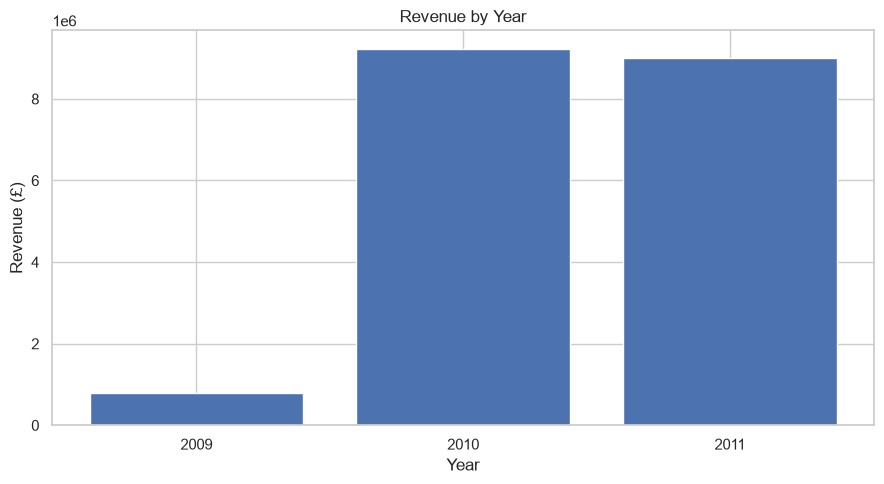

In [71]:
yearly = (
    df.groupby("Year")
      .agg(
          Net_Revenue=("Revenue", "sum"),
          Quantity=("Quantity", "sum"),
          Invoices=("Invoice", "nunique")
      )
      .reset_index()
)

display(yearly)

yearly.to_csv(output_dir / "revenue_by_year.csv", index=False)

plt.figure(figsize=(9, 5))
plt.bar(
    yearly["Year"].astype(str),
    yearly["Net_Revenue"]
)
plt.title("Revenue by Year")
plt.xlabel("Year")
plt.ylabel("Revenue (£)")
plt.tight_layout()
plt.savefig(
    visualization_dir / "revenue_by_year.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

## 7. Product Analysis

Product performance is evaluated using **sales transactions only**.

Two separate measures are important:
1. Revenue contribution
2. Quantity sold

This prevents a high-volume, low-value product from being confused with a high-value product.

In [72]:
product_analysis = (
    sales_df.groupby(["StockCode", "Description"], dropna=False)
            .agg(
                Quantity_Sold=("Quantity", "sum"),
                Revenue=("Revenue", "sum"),
                Transactions=("Invoice", "size")
            )
            .reset_index()
)

top_products_revenue = (
    product_analysis
    .sort_values("Revenue", ascending=False)
    .head(10)
    .copy()
)

top_products_quantity = (
    product_analysis
    .sort_values("Quantity_Sold", ascending=False)
    .head(10)
    .copy()
)

display(top_products_revenue)
display(top_products_quantity)

top_products_revenue.to_csv(output_dir / "top_products_by_revenue.csv", index=False)
top_products_quantity.to_csv(output_dir / "top_products_by_quantity.csv", index=False)

# Compatibility copies used in earlier project outputs
top_products_revenue.to_csv(output_dir / "top_products_revenue.csv", index=False)
top_products_quantity.to_csv(output_dir / "top_products_quantity.csv", index=False)

,StockCode,Description,Quantity_Sold,Revenue,Transactions
5875,M,Manual,9636,"339,226.24",853
1985,22423,REGENCY CAKESTAND 3 TIER,26495,"330,590.32",3954
5874,DOT,DOTCOM POSTAGE,2920,"309,854.11",1422
5248,85123A,WHITE HANGING HEART T-LIGHT HOLDER,94147,"257,546.20",5507
3505,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,"168,469.60",1
3893,47566,PARTY BUNTING,28248,"148,318.28",2708
5214,85099B,JUMBO BAG RED RETROSPOT,77286,"145,961.83",3291
4867,84879,ASSORTED COLOUR BIRD ORNAMENT,80090,"129,324.49",2849
5877,POST,POSTAGE,10313,"125,682.42",1858
1556,22086,PAPER CHAIN KIT 50'S CHRISTMAS,35113,"117,760.29",2069


,StockCode,Description,Quantity_Sold,Revenue,Transactions
4384,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,106250,"24,445.61",1024
5248,85123A,WHITE HANGING HEART T-LIGHT HOLDER,94147,"257,546.20",5507
3505,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,"168,469.60",1
4867,84879,ASSORTED COLOUR BIRD ORNAMENT,80090,"129,324.49",2849
2949,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,"81,700.92",250
5214,85099B,JUMBO BAG RED RETROSPOT,77286,"145,961.83",3291
127,17003,BROCADE RING PURSE,70379,"14,766.42",463
1458,21977,PACK OF 60 PINK PAISLEY CAKE CASES,56061,"28,081.73",2025
5040,84991,60 TEATIME FAIRY CAKE CASES,54028,"27,041.21",2179
1694,22197,SMALL POPCORN HOLDER,48597,"42,699.89",1433


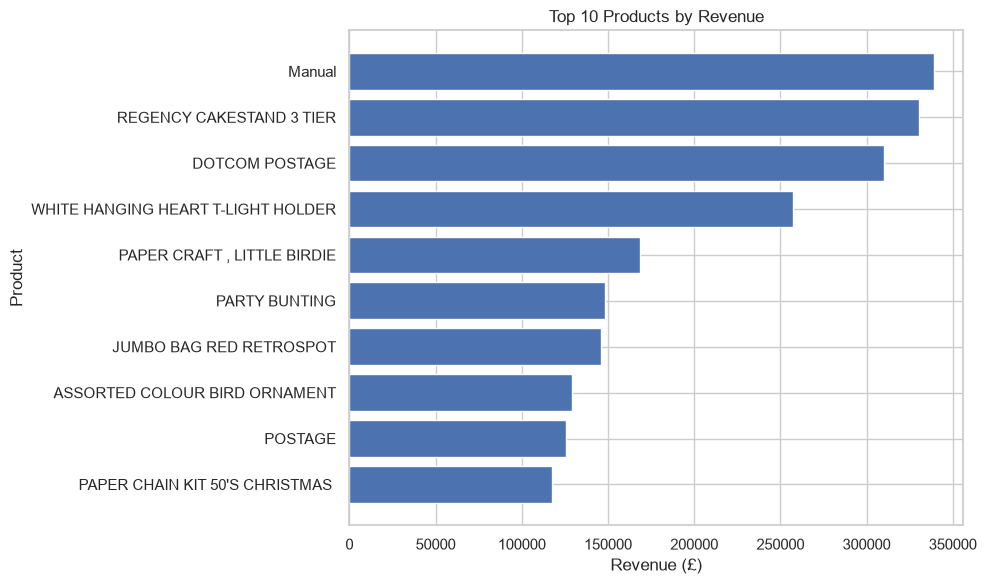

In [73]:
# Top 10 products by revenue
plot_data = top_products_revenue.sort_values("Revenue")

plt.figure(figsize=(10, 6))
plt.barh(
    plot_data["Description"].fillna("Unknown").astype(str),
    plot_data["Revenue"]
)
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.savefig(
    visualization_dir / "top_products_by_revenue.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

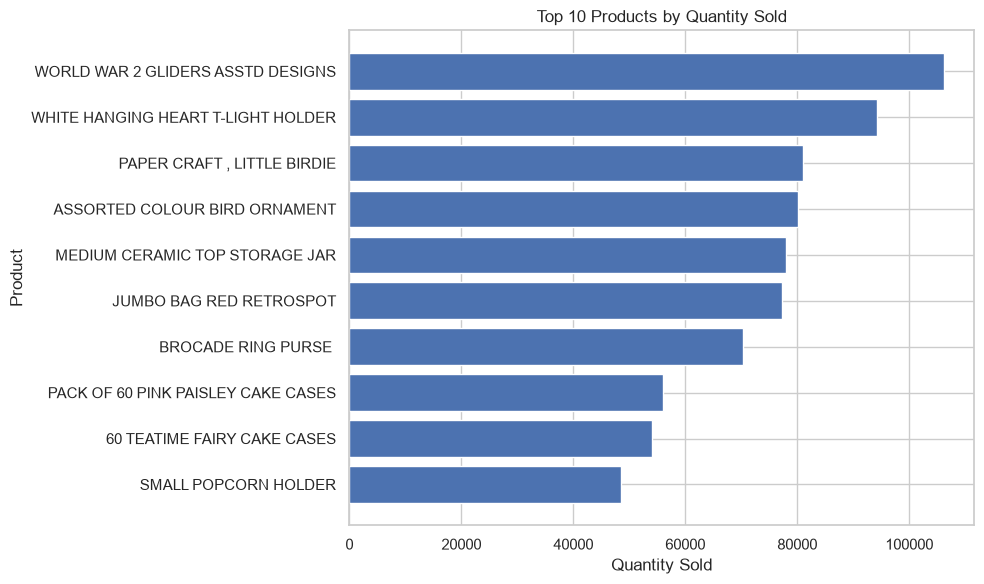

In [74]:
# Top 10 products by quantity
plot_data = top_products_quantity.sort_values("Quantity_Sold")

plt.figure(figsize=(10, 6))
plt.barh(
    plot_data["Description"].fillna("Unknown").astype(str),
    plot_data["Quantity_Sold"]
)
plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.savefig(
    visualization_dir / "top_products_by_quantity.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

## 8. Country Analysis

Country performance is measured in two ways:
- Number of transactions/invoices
- Sales revenue

This allows us to distinguish market activity from market value.

In [75]:
country_analysis = (
    sales_df.groupby("Country")
            .agg(
                Revenue=("Revenue", "sum"),
                Quantity=("Quantity", "sum"),
                Transactions=("Invoice", "size"),
                Unique_Invoices=("Invoice", "nunique")
            )
            .reset_index()
            .sort_values("Revenue", ascending=False)
)

display(country_analysis.head(10))

country_analysis.to_csv(output_dir / "country_analysis.csv", index=False)

,Country,Revenue,Quantity,Transactions,Unique_Invoices
40,United Kingdom,"17,410,196.12",9437244,928632,38395
11,EIRE,"658,767.31",336604,17159,626
26,Netherlands,"554,038.09",384519,5090,229
15,Germany,"425,019.71",225173,16440,789
14,France,"350,456.09",271902,13640,622
0,Australia,"169,283.46",104067,1792,95
34,Spain,"108,332.49",50318,3663,154
36,Switzerland,"100,685.59",52763,3123,93
35,Sweden,"91,869.82",88633,1336,105
10,Denmark,"68,580.69",237471,778,43


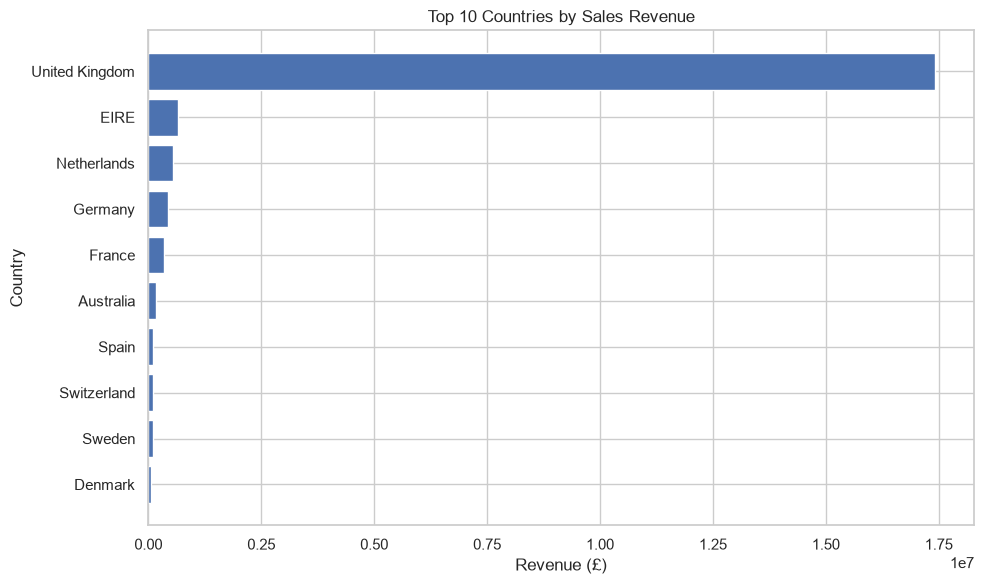

In [76]:
# Top 10 countries by revenue
top_countries_revenue = (
    country_analysis
    .sort_values("Revenue", ascending=False)
    .head(10)
    .sort_values("Revenue")
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_countries_revenue["Country"],
    top_countries_revenue["Revenue"]
)
plt.title("Top 10 Countries by Sales Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.savefig(
    visualization_dir / "top_countries_by_revenue.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

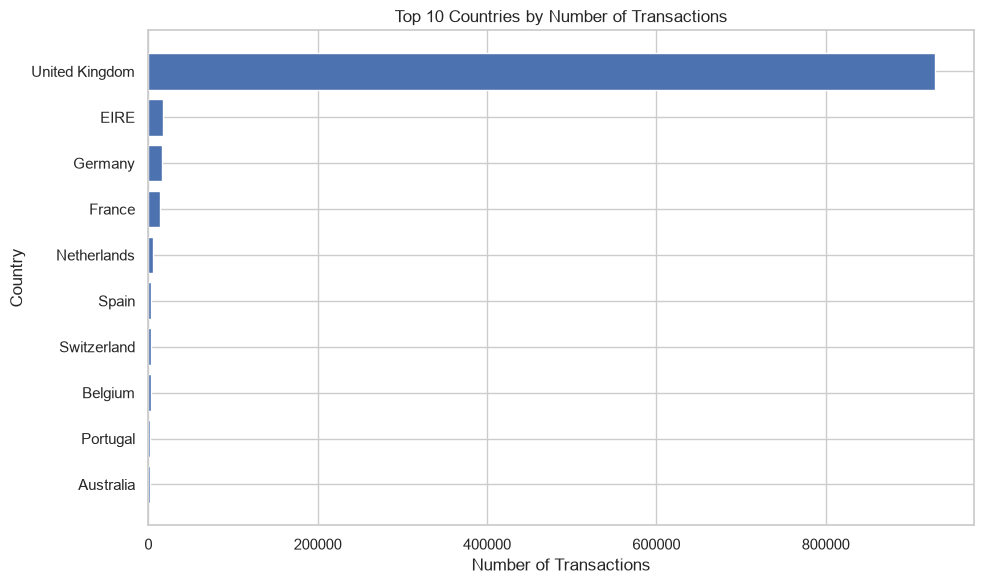

In [77]:
# Top 10 countries by transaction count
top_countries_transactions = (
    country_analysis
    .sort_values("Transactions", ascending=False)
    .head(10)
    .sort_values("Transactions")
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_countries_transactions["Country"],
    top_countries_transactions["Transactions"]
)
plt.title("Top 10 Countries by Number of Transactions")
plt.xlabel("Number of Transactions")
plt.ylabel("Country")
plt.tight_layout()
plt.savefig(
    visualization_dir / "top_countries_by_transactions.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

## 9. Customer Analysis

Customer analysis uses only records with an identified `Customer ID`.

Missing Customer IDs are not treated as zero or assigned to a fake customer.

In [78]:
customer_df = sales_df.dropna(subset=["Customer ID"]).copy()

customer_analysis = (
    customer_df.groupby("Customer ID")
               .agg(
                   Revenue=("Revenue", "sum"),
                   Quantity=("Quantity", "sum"),
                   Transactions=("Invoice", "size"),
                   Unique_Invoices=("Invoice", "nunique")
               )
               .reset_index()
               .sort_values("Revenue", ascending=False)
)

top_customers = customer_analysis.head(10).copy()

display(top_customers)

customer_analysis.to_csv(output_dir / "customer_analysis.csv", index=False)
top_customers.to_csv(output_dir / "customer_revenue.csv", index=False)

,Customer ID,Revenue,Quantity,Transactions,Unique_Invoices
5695,"18,102.00","580,987.04",181645,1040,145
2279,"14,646.00","528,602.52",367833,3854,152
1791,"14,156.00","313,437.62",164325,4038,156
2541,"14,911.00","291,420.81",148222,11079,398
5053,"17,450.00","244,784.25",84562,421,51
1332,"13,694.00","195,640.69",188201,1519,143
5112,"17,511.00","172,132.87",117174,1868,60
4064,"16,446.00","168,472.50",80997,3,2
4298,"16,684.00","147,142.77",104810,718,55
68,"12,415.00","144,458.37",91743,928,28


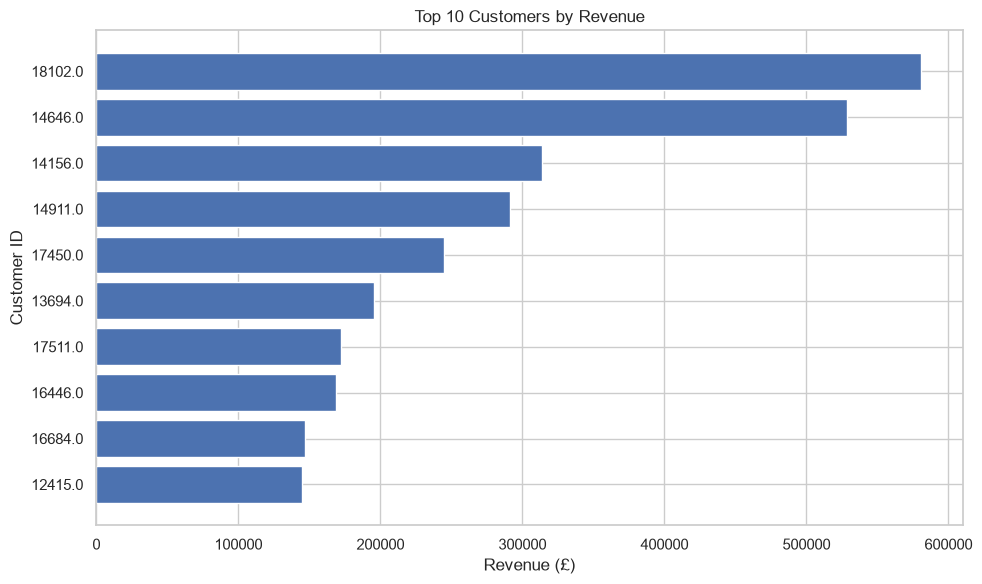

In [79]:
plot_data = top_customers.sort_values("Revenue")

plt.figure(figsize=(10, 6))
plt.barh(
    plot_data["Customer ID"].astype(str),
    plot_data["Revenue"]
)
plt.title("Top 10 Customers by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.savefig(
    visualization_dir / "top_customers_by_revenue.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

## 10. Cancellation and Return Analysis

Negative quantities are analyzed separately because they can represent:
- Product returns
- Order cancellations
- Other legitimate business adjustments

The financial impact is measured through negative revenue.

In [80]:
return_df = df[df["Quantity"] < 0].copy()

return_summary = pd.Series({
    "Negative-quantity records": len(return_df),
    "Negative quantity": return_df["Quantity"].sum(),
    "Return/cancellation revenue impact": return_df["Revenue"].sum(),
    "Average return/cancellation revenue": return_df["Revenue"].mean()
})

display(return_summary.to_frame("Value"))
return_summary.to_frame("Value").to_csv(output_dir / "return_summary.csv")

,Value
Negative-quantity records,"22,496.00"
Negative quantity,"-1,046,134.00"
Return/cancellation revenue impact,"-1,462,424.18"
Average return/cancellation revenue,-65.01


,YearMonth,Return_Quantity,Return_Revenue_Impact,Return_Transactions
0,2009-12,-25771,"-25,835.45",1103
1,2010-01,-20724,"-28,675.61",814
2,2010-02,-24360,"-20,612.93",1022
3,2010-03,-42302,"-67,668.02",1031
4,2010-04,-35270,"-37,354.20",701
5,2010-05,-61238,"-44,434.78",1350
6,2010-06,-27276,"-72,463.44",930
7,2010-07,-57415,"-31,444.79",822
8,2010-08,-70987,"-40,477.52",664
9,2010-09,-115807,"-70,591.03",900


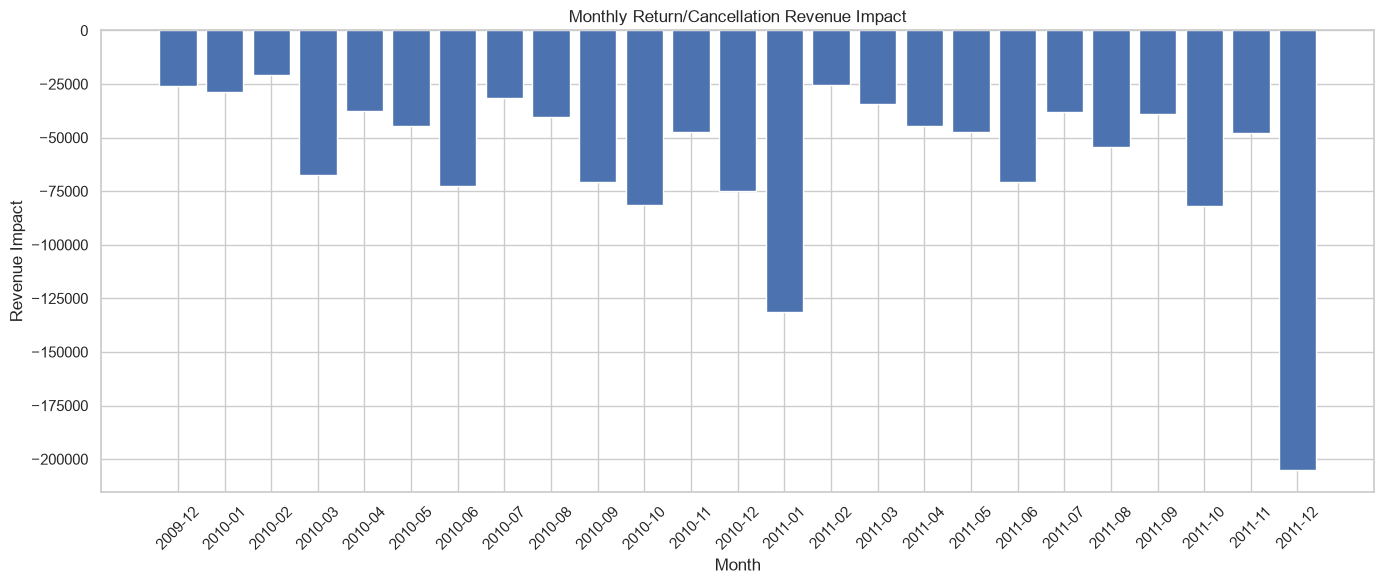

In [86]:
monthly_returns = (
    return_df.assign(
        YearMonth=return_df["InvoiceDate"].dt.to_period("M").astype(str)
    )
    .groupby("YearMonth")
    .agg(
        Return_Quantity=("Quantity", "sum"),
        Return_Revenue_Impact=("Revenue", "sum"),
        Return_Transactions=("Invoice", "size")
    )
    .reset_index()
)

display(monthly_returns)

monthly_returns.to_csv(output_dir / "monthly_return_impact.csv", index=False)

plt.figure(figsize=(14, 6))
plt.bar(
    monthly_returns["YearMonth"],
    monthly_returns["Return_Revenue_Impact"]
)
plt.title("Monthly Return/Cancellation Revenue Impact")
plt.xlabel("Month")
plt.ylabel("Revenue Impact")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    visualization_dir / "monthly_return_impact.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

## 11. Anomaly Detection

An IQR-based method is used to identify unusually high positive sales-line revenue values.

**Important:** A statistical outlier is not automatically an error, fraud, or invalid transaction. It is a record that deserves further investigation.

In [82]:
positive_revenue = sales_df.loc[
    sales_df["Revenue"] > 0,
    "Revenue"
]

q1 = positive_revenue.quantile(0.25)
q3 = positive_revenue.quantile(0.75)
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr

high_value_anomalies = sales_df[
    sales_df["Revenue"] > upper_bound
].copy()

anomaly_summary = pd.Series({
    "Q1": q1,
    "Q3": q3,
    "IQR": iqr,
    "Upper bound": upper_bound,
    "Potential high-value anomaly records": len(high_value_anomalies)
})

display(anomaly_summary.to_frame("Value"))

high_value_anomalies.to_csv(
    output_dir / "high_value_anomalies.csv",
    index=False
)

,Value
Q1,4.13
Q3,17.70
IQR,13.57
Upper bound,38.06
Potential high-value anomaly records,"84,954.00"


## 12. Key Insight Evidence

The next cell calculates the numerical evidence used in the final report and presentation.

**Do not manually type these values into the final submission.** Let the notebook calculate them from the dataset so the results remain reproducible.

In [83]:
top_country = country_analysis.iloc[0]
top_product = top_products_revenue.iloc[0]
top_customer = customer_analysis.iloc[0]

top_10_product_share = (
    top_products_revenue["Revenue"].sum()
    / sales_df["Revenue"].sum()
    * 100
)

top_10_customer_share = (
    top_customers["Revenue"].sum()
    / customer_analysis["Revenue"].sum()
    * 100
)

peak_month = monthly.loc[
    monthly["Net_Revenue"].idxmax()
]

key_insights = pd.DataFrame({
    "Metric": [
        "Total net revenue",
        "Total sales revenue",
        "Top country by sales revenue",
        "Top country sales revenue",
        "Top country share of sales revenue (%)",
        "Top product by sales revenue",
        "Top product revenue",
        "Top 10 products revenue share (%)",
        "Top customer ID",
        "Top customer revenue",
        "Top 10 customers revenue share (%)",
        "Peak net-revenue month",
        "Peak net revenue",
        "Return/cancellation revenue impact",
        "Potential high-value anomaly records"
    ],
    "Value": [
        df["Revenue"].sum(),
        sales_df["Revenue"].sum(),
        top_country["Country"],
        top_country["Revenue"],
        top_country["Revenue"] / sales_df["Revenue"].sum() * 100,
        top_product["Description"],
        top_product["Revenue"],
        top_10_product_share,
        top_customer["Customer ID"],
        top_customer["Revenue"],
        top_10_customer_share,
        peak_month["YearMonth"],
        peak_month["Net_Revenue"],
        return_df["Revenue"].sum(),
        len(high_value_anomalies)
    ]
})

display(key_insights)

key_insights.to_csv(
    output_dir / "key_insight_evidence.csv",
    index=False
)

,Metric,Value
0,Total net revenue,"19,014,209.84"
1,Total sales revenue,"20,476,260.45"
2,Top country by sales revenue,United Kingdom
3,Top country sales revenue,"17,410,196.12"
4,Top country share of sales revenue (%),85.03
5,Top product by sales revenue,Manual
6,Top product revenue,"339,226.24"
7,Top 10 products revenue share (%),10.12
8,Top customer ID,"18,102.00"
9,Top customer revenue,"580,987.04"


## 13. Final Business Insights

Use the calculated evidence above to write the final interpretation.

### Insight 1 – Revenue Trend
Revenue varies substantially across months, with a clear peak month identified by the monthly revenue analysis.

### Insight 2 – Geographic Concentration
The United Kingdom is the dominant sales market in the dataset.

### Insight 3 – Product Performance
The highest-revenue products and highest-quantity products are not necessarily the same, showing the importance of analyzing both value and volume.

### Insight 4 – Customer Contribution
A small group of identified customers contributes a meaningful share of identified-customer revenue, supporting key-account analysis.

### Insight 5 – Returns and Cancellations
Negative-quantity transactions create a measurable negative revenue impact and should be monitored as part of operational performance.

### Insight 6 – Anomaly Screening
The IQR method identifies a set of unusually high-value sales lines for further investigation. These are potential anomalies, not automatically errors.

## 14. Final Validation

This is the final checkpoint before submission.

Expected checks:
- No duplicate records after Task 1 cleaning
- No missing invoice dates
- All required analysis outputs generated
- All required visualization files generated

In [84]:
required_visualizations = [
    "transaction_type_distribution.png",
    "monthly_revenue_trend.png",
    "revenue_by_year.png",
    "top_products_by_revenue.png",
    "top_products_by_quantity.png",
    "top_countries_by_revenue.png",
    "top_countries_by_transactions.png",
    "top_customers_by_revenue.png",
    "monthly_return_impact.png"
]

missing_visualizations = [
    name for name in required_visualizations
    if not (visualization_dir / name).exists()
]

print("=" * 60)
print("TASK 2 — EDA FINAL VALIDATION")
print("=" * 60)
print(f"Dataset shape       : {df.shape}")
print(f"Duplicate records   : {df.duplicated().sum()}")
print(f"Missing dates       : {df['InvoiceDate'].isna().sum()}")
print(f"Total net revenue   : £{df['Revenue'].sum():,.2f}")
print(f"Total sales revenue : £{sales_df['Revenue'].sum():,.2f}")
print(f"Number of products  : {df['StockCode'].nunique():,}")
print(f"Number of countries : {df['Country'].nunique():,}")
print(f"Customers identified: {customer_df['Customer ID'].nunique():,}")
print(f"Required charts     : {len(required_visualizations)}")
print(f"Missing charts      : {missing_visualizations}")
print("=" * 60)

if df.duplicated().sum() == 0 and df["InvoiceDate"].isna().sum() == 0 and not missing_visualizations:
    print("EDA analysis completed successfully.")
else:
    print("WARNING: Review the validation results above before submission.")

TASK 2 — EDA FINAL VALIDATION
Dataset shape       : (1033031, 16)
Duplicate records   : 0
Missing dates       : 0
Total net revenue   : £19,014,209.84
Total sales revenue : £20,476,260.45
Number of products  : 5,305
Number of countries : 43
Customers identified: 5,881
Required charts     : 9
Missing charts      : []
EDA analysis completed successfully.


## 15. Output Files

### Analysis tables
The notebook creates:
- `eda_data_quality.csv`
- `summary_statistics.csv`
- `transaction_summary.csv`
- `monthly_revenue.csv`
- `revenue_by_year.csv`
- `top_products_by_revenue.csv`
- `top_products_by_quantity.csv`
- `country_analysis.csv`
- `customer_analysis.csv`
- `customer_revenue.csv`
- `return_summary.csv`
- `monthly_return_impact.csv`
- `high_value_anomalies.csv`
- `key_insight_evidence.csv`

### Visualizations
The notebook creates:
- `transaction_type_distribution.png`
- `monthly_revenue_trend.png`
- `revenue_by_year.png`
- `top_products_by_revenue.png`
- `top_products_by_quantity.png`
- `top_countries_by_revenue.png`
- `top_countries_by_transactions.png`
- `top_customers_by_revenue.png`
- `monthly_return_impact.png`

These outputs can be used in the GitHub repository, internship submission, presentation, and future dashboard work.

## 16. Conclusion

This EDA transforms the cleaned Online Retail II dataset into a set of reproducible business insights covering revenue, products, geography, customers, returns/cancellations, and unusual high-value transactions.

The analysis keeps meaningful business events such as returns and cancellations visible, separates sales revenue from net revenue where appropriate, and uses statistical anomaly detection as an investigation aid rather than automatically deleting unusual records.

**Task 2 is complete when the final validation cell passes successfully and all required output files and visualizations are generated.**